# Functional Principal Component Analysis with Partial Differential Equation Regularization

fdaPDE Team, MOX, Department of Mathematics, Politecnico di Milano, Italy

`fdaPDE` (Palummo et al., 2025) is a C++ library with an interface to R for *physics-informed spatial and functional data analysis*, at the intersection of statistics and numerical analysis. The library provides advanced statistical methods designed for data located over complex spatial domains, ranging from irregular planar regions and curved surfaces to linear networks and volumes, possibly evolving over time. The class of methods implemented in `fdaPDE` features regularization terms based on Partial Differential Equations (PDEs), which allow incorporating information derived from the physics of the problem under study into the statistical modeling. This makes `fdaPDE` an extremely flexible tool for the analysis of complex data. For a review of this class of methods, refer to @sangalli2021spatial.

`fdaPDE` offers a wide range of modeling capabilities -- including regression, nonparametric density estimation, functional data analysis, and more -- for data located over a spatial domain, possibly evolving over time. Among the broad range of modeling capabilities offered by `fdaPDE`, we focus here on the **functional principal component analysis**.

## Model

**Functional Principal Component Analysis** (fPCA) extends the traditional multivariate PCA to the case of functional data. The idea of fPCA is to describe the variability of functional data, namely smooth functions evaluated over a grid of points, as a linear combination of smooth basis functions called functional principal components (fPCs). This data summary provides insights into the dominant modes of variation and possibly allows for dimensionality reduction, considering only the principal components associated with a sufficient portion of variability. These properties make fPCA a valuable tool in functional data analysis (FDA).

We present the fPCA model derived in @lila2016smooth, which proposes to minimize the following functional:

$$
J(\{f_m\}, S) = \sum_{i=1}^n \sum_{j=1}^l \left (x_{ij}-\sum_{m=1}^r s_{mi}f_m(\mathbf{p}_j) \right )^2 +  \sum_{m=1}^r \lambda_m \|\mathbf{s}_m\|_2^2 \int_{\mathcal{D}} (\Delta f_m(\mathbf{p}))^2 \, \text{d}\mathbf{p}\,.
$$
The first term encodes the **data-fidelity** of the estimates using the characterization of fPCA as the best $r-$basis approximation of the data. In particular, $x_{ij}$ is the value of the observed function for subject $i$ at spatial location $\mathbf{p}_j\,,$ for $i=1,\ldots,n$ and $j=1,\ldots,l\,;$ $s_{mi}$ represents the Principal Component (PC) score of the $i$th subject along component $m\,,$ for $m = 1,\ldots,r\,;$ $f_m(\mathbf{p}_j)$ is the value of the $m$th fPC at location $\mathbf{p}_j\,.$ The second term promote the **smoothness** of the estimated fPCs to account for the functional nature of the data. The trade-off between data-fidelity and smoothness of the fPCs is balanced by the $\{\lambda_m\}_m$ **smoothing parameters**, which can be selected using data-driven criteria, such as the minimization of **Generalized Cross-Validation** (GCV).

The method for Functional Principal Component Analysis presented in this vignette is implemented within the newest version of the `fdaPDE` C++ library (Palummo et al., 2025). We load the library in the working environment as follows:

In [1]:
# Google Colab setup. Skip this cell when running locally.
if (any(nzchar(Sys.getenv(c(
  "COLAB_RELEASE_TAG",
  "COLAB_BACKEND_VERSION"
))))) {

  # Download the repository.
  repository <- "/content/course-materials"

  if (!dir.exists(repository)) {
    stopifnot(system2(
      "git",
      c(
        "clone", "--depth", "1",
        "https://github.com/fdaPDE/course-materials.git",
        shQuote(repository)
      )
    ) == 0L)
  }

  # Set the working directory and configure dependencies.
  setwd(file.path(
    repository,
    "courses",
    "[2026-Lancaster]-Physics-Informed-Statistical-Learning-for-Spatial-and-Functional-Data",
    "R", "notebook"
  ))

  source("../utils/colab_setup.R")
}

In [2]:
rm(list = ls())

# Import the fdaPDE library
# Load additional libraries and helper functions for plotting
suppressPackageStartupMessages({
    library(fdaPDE2)
    source("../utils/graphics.R")
  })

In [3]:
par(
  cex       = 1.2,                  # text size ~12pt
  font.main = 2,                    # bold plot titles
  cex.main  = 1.4,                  # title size ~14pt
  col.main  = "black",              # title color
  mar       = c(5, 4, 4, 2) + 0.1,  # margins (bottom, left, top, right)
  las       = 1                     # horizontal axis labels
)

## Application to spatial transcriptomics data

As a benchmark application in genomics, we analyze data from patients with a **HER2-positive breast tumor**. The dataset consists of measurements of gene expression levels across a section of breast cancer tissue. Gene expression levels are quantified by counting the number of times each gene is transcribed at specific spatial locations, using spatial transcriptomics techniques. In this analysis, we focus on gene expression data from a single patient.

Below is a histological image of the tissue under study, annotated by a pathologist as detailed in @shang2022spatially.

![Histological image](../../data/fPCA_2D/fPCA_2D_histological_image.png)

<div style="text-align: center;">
Figure 1: Histological image of the tissue under study.
</div>

We introduce the following terminology:

* **DCIS (Ductal Carcinoma In Situ):** an early, non-invasive form of breast cancer in which abnormal cells are confined to the milk ducts and have not spread to surrounding tissues;

* **Immune Cells:** cells that are part of the immune system, responsible for defending the body against infections and disease.

### 1. Data

The data -- preprocessed following the procedure described in @shang2022spatially -- comprise expression levels of 302 genes measured at 604 spatial locations across the tissue, represented as a two-dimensional domain.

In [4]:
## [DATA]
# Load the data
counts <- as.matrix(read.csv("../../data/fPCA_2D/fPCA_2D_counts.csv", row.names = 1))
locations <- read.csv(file = "../../data/fPCA_2D/fPCA_2D_locations.csv", row.names = 1)

# Data content
# - locations:      (data.frame)    n_locations x 2
# - counts:         (dgCMatrix)     n_genes x n_locations

# Gene names
gene_names <- names(counts[,1])

We visualize the expression of the *ERBB2* gene, which encodes the HER2 protein. It is well established that overexpression of *ERBB2* is a key biomarker for breast cancer. In particular, the tumor under study has been identified as HER2-positive. As expected, the expression of *ERBB2* is elevated in regions annotated as cancerous by the pathologist, reflecting the gene's central role in tumor progression.

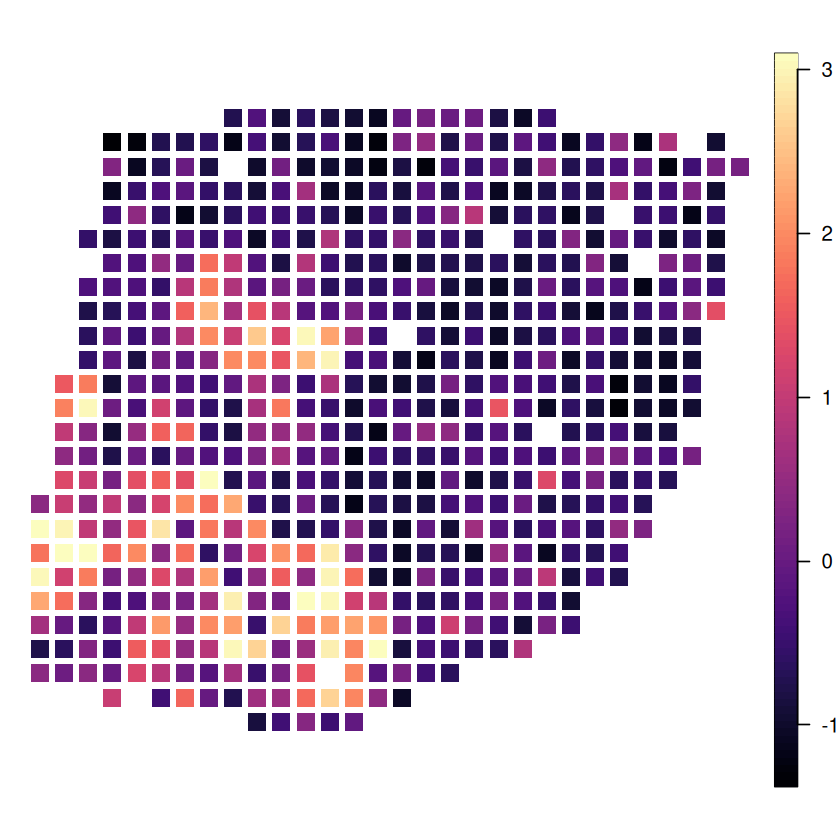

In [5]:
# ERB22-gene index
idx.HER2 <- 22

n_col <- 100
palette_ <- magma(n_col)
vals <- counts[idx.HER2,]
col <- palette_[as.numeric(cut(vals, breaks = n_col))]

par(oma = c(0, 0, 0, 0))
par(mar = c(0.5, 0.5, 0.5, 3))
plot(
    locations[, 1], locations[, 2], 
    xlab = "", ylab = "", 
    pch = 15, col = col, asp = 1, cex = 2, 
    frame.plot=F, xaxt="n", yaxt="n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(vals, na.rm = TRUE), 
    col         = palette_, 
    legend.args = list(side = 4), 
    legend.lab  = "", 
    legend.mar  = 2.25
)

![Histological image](../../data/fPCA_2D/fPCA_2D_reduced_histological_image.png)

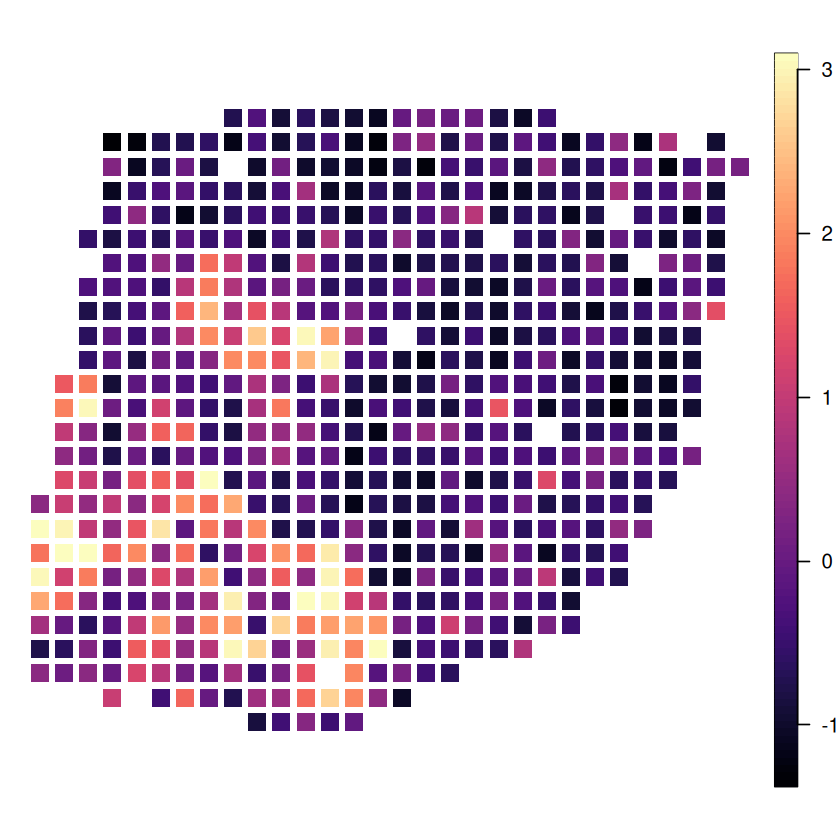

In [6]:
# Static plot
par(oma = c(0, 0, 0, 0))
par(mar = c(0.5, 0.5, 0.5, 3))
plot(
    locations[, 1], locations[, 2], 
    xlab = "", ylab = "", pch = 15,
    col = col, asp = 1, cex = 2, 
    frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(vals, na.rm = TRUE),
    col         = palette_, 
    legend.args = list(side = 4),
    legend.lab  = "", 
    legend.mar  = 2.25
)

:::
:::::

<div style="text-align: center;">
Figure 2: Reduced histological image of the tissue under study (left); expression of the *ERBB2* gene (right).
</div>

### 2. Spatial domain

We now proceed with the fPCA analysis. As a first step, we build a **regular mesh** of the spatial domain under consideration, based on the sampling locations. Then we refine it by setting the maximum element area to 0.1 and the minimum angle to 30 degrees. The triangulation is constructed using the `RTriangle` [@shewchuk2025RTriangle] R package. Other software can be used to get the triangulation; for example, it can be constructed through the `fmesher` [@lindgren2025fmesher] R package.

In [7]:
## [MESH]
# Create a planar straight line graph object
p <- pslg(P = locations)

# Create a regular mesh of the spatial domain
mesh <- triangulate(p, Y = FALSE, D = TRUE)
if (is.null(mesh$H)) mesh$H <- matrix(numeric(0), ncol = 2)

# Create a regular mesh of the spatial domain
mesh <- triangulate(mesh, a = 0.1, q = 30, D = TRUE)

We convert the `triangulation` object from `RTriangle` so that it can be read by `fdaPDE`.

In [8]:
# Set up the triangulation for fdaPDE
mesh_tissue <- triangulation(
  nodes    = mesh$P,
  cells    = mesh$T,
  boundary = mesh$PB
)

The next objective is to visualize the fPCs in order to examine the most significant modes of variation in the data. We fit the model to the centered data, as fPCA assumes that the input functions have **zero mean**. 

We use the triangulation just created to define the spatial support of a `geoframe` object. This object will host layers containing data observed over the spatial support.

In [9]:
# Create the geoframe
tissue <- geoframe(domain = mesh_tissue)
tissue

Geoframe with 0 layers
Bounding box:    xmin: 3 ymin: -34 xmax: 32 ymax: -9
Number of nodes: 4881
Number of cells: 9513


We add a data layer to the `geoframe` object defined above, thus obtaining a format compatible with the implementation of the proposed smoothing method.

In [10]:
# Add layer with data to the geoframe object
tissue$insert(
    layer = "sample_mean", 
    type  = "point", 
    geo   = locations, 
    data  = data.frame(sample_mean = colMeans(counts))
)
tissue

Geoframe with 1 layers
Bounding box:    xmin: 3 ymin: -34 xmax: 32 ymax: -9
Number of nodes: 4881
Number of cells: 9513

Layer: sample_mean
Type:  POINT
Dims: 607, 1
First 6 data rows:
sample_mean 
<flt64>     
-0.131431   
-0.0302343  
-0.0824803  
-0.0352357  
-0.101357   
-0.21352    

### 3. Smooth approximation of the mean function

We apply smoothing to the column-wise means to derive a smooth approximation of the mean function. Here, the optimal smoothing parameter is selected via GCV minimization using grid search method. This technique requires the stochastic computation of the degrees of freedom.

In [11]:
## [ISOTROPIC SMOOTHING WITH OPTIMAL SMOOTHING PARAMETER]
# Set up the finite element function (order 1)
f <- fe_function(domain = mesh_tissue, type = "P1")

# Proposed values for the smoothing parameter
lambda_grid <- 10^seq(from = -5, to = -2, length.out = 10)

# Isotropic smoothing model
smoothing_model <- sr(formula = sample_mean ~ f, data = tissue)

# Isotropic smoothing fit
smoothing_fit <- smoothing_model$fit(
  calibrator = gcv(
    optimizer = grid_search(grid = lambda_grid)
  )
)

We visualize the mean as follows:

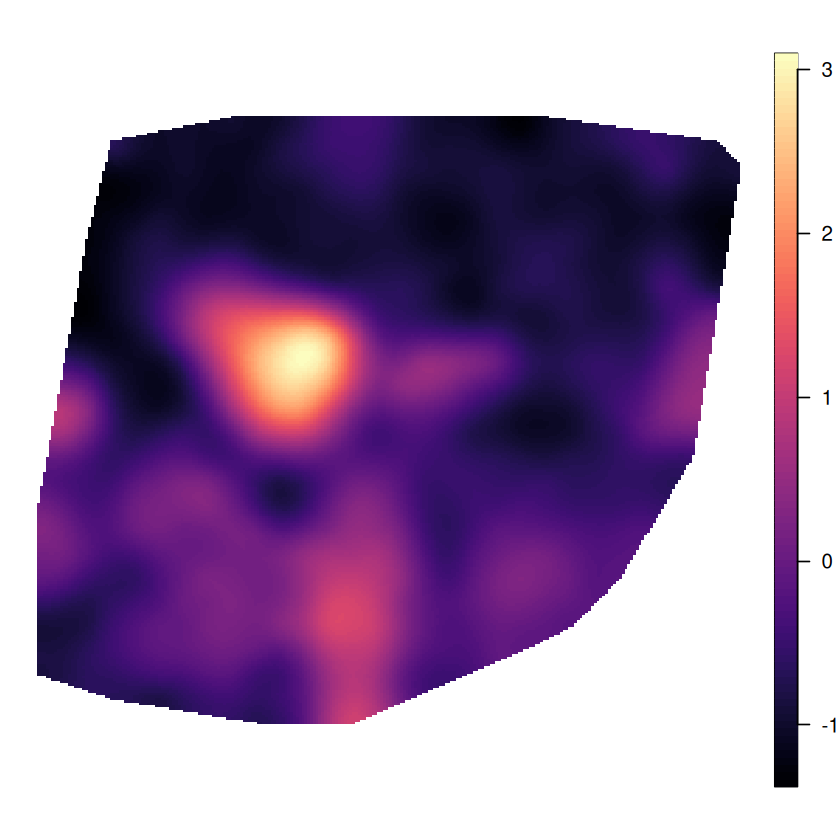

In [12]:
# Static plot
par(mar = c(0.5, 0.5, 0.5, 3), oma = c(0, 0, 0, 0), mfrow = c(1,1))
plot(
    f, 
    palette = magma, frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(vals, na.rm = TRUE),
    col         = palette_, 
    legend.args = list(side = 4),  
    legend.lab  = "", legend.mar = 2.25
)

<div style="text-align: center;">
Figure 3: Smooth approximation of the mean function.
</div>

### 4. fPCA to the centered data

We are now ready to fit the fPCA model to the centered data. First, we construct a new `geoframe` object.

In [13]:
# Center the data
centered_counts <- sweep(counts, 2, smoothing_model$fitted, FUN = "-")

# Create the geoframe
tissue_fpca <- geoframe(domain = mesh_tissue)

# Add layer with data to the geoframe object
tissue_fpca$insert("gene_expression", type = "point", geo = locations)
tissue_fpca[["gene_expression"]]$X <- t(centered_counts)

We perform fPCA with the `fpca` function, setting to 6 the number of PCs to be extracted. For further information, see the documentation by typing `?fpca`.

In [14]:
## [FUNCTIONAL PRINCIPAL COMPONENT ANALYSIS]
# fPCA model
fpca_model <- fpca(column = "X", data = tissue_fpca)

# Proposed values for the smoothing parameter
lambda_grid <- 10^seq(from = -2, to = 2, by = 0.5)

# fPCA fit
fpca_fit <- fpca_model$fit(
  npc = 6,
  calibrator = gcv(
    optimizer = grid_search(grid = lambda_grid)
  )
)

We visualize the **proportion of explained variance** to determine the *optimal number of principal components*. A noticeable increase in explained variance is observed between the third and fourth components, suggesting that retaining the first three fPCs may be appropriate.

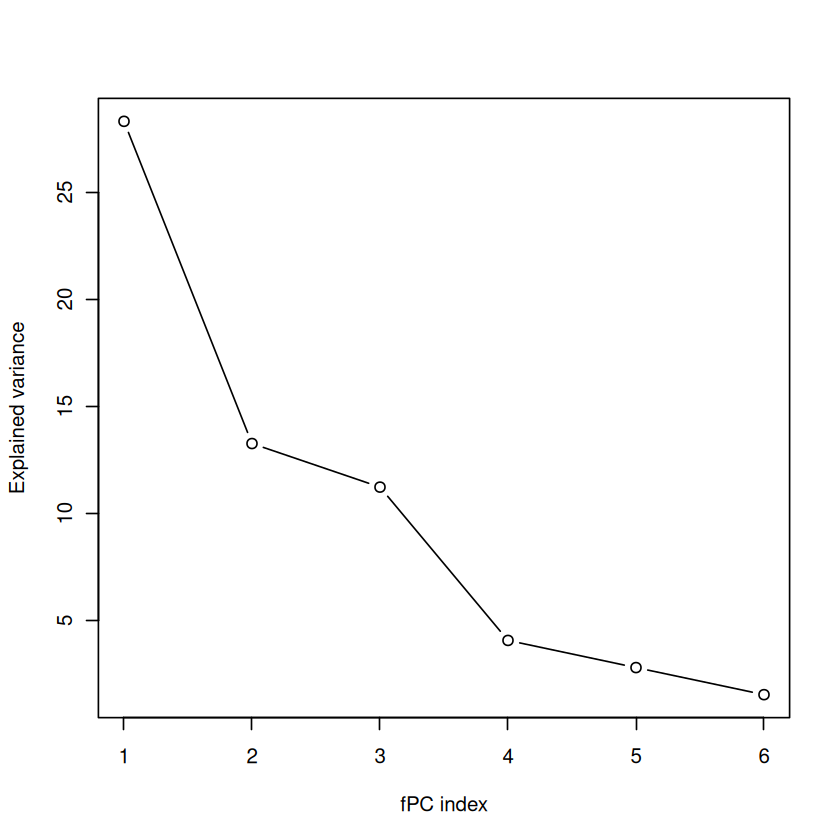

In [15]:
# Explained variance
plot(apply(X = fpca_model$scores, MARGIN = 2, FUN = var), type = "b", xlab = "fPC index", ylab = "Explained variance")

<div style="text-align: center;">
Figure 4: Proportion of explained variance.
</div>
 
According to the figure above, we select 3 PCs and compute fPCs accordingly.

In [16]:
# Select the optimal number of PCs
npc <- 3

# fPCs
fPCs <- fpca_model$pcs[,1:npc]
for (i in 1:npc) {
  # Flip fPCs to have coherent signs in the visualization
  if (max(fPCs[, i], na.rm = T) < -min(fPCs[, i], na.rm = T)) {
    fPCs[, i] <- -fPCs[, i]
  }
}

Finally, the extracted fPCs can be visualized as follows:

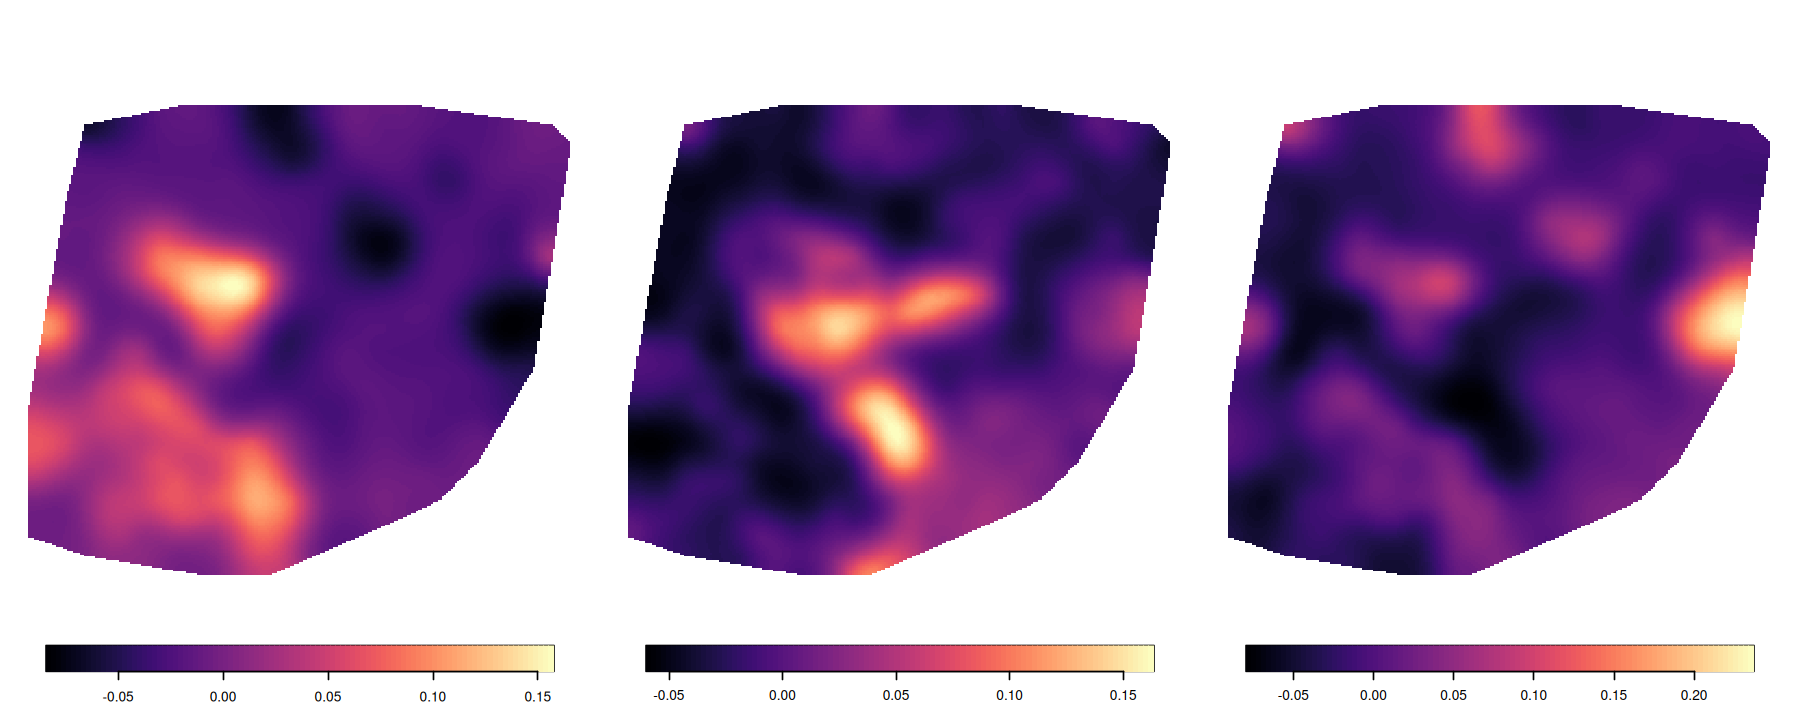

In [17]:
# Static plot
old_plot_size <- options(repr.plot.width = 15, repr.plot.height = 6)
par(mfrow = c(1,3), mar = c(3, 0.5, 0.5, 0.5), oma = c(0, 0, 0, 0))
plot(
    fe_function(domain = mesh_tissue, coeff=fPCs[,1], type = "P1"), 
    palette = magma, 
    frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(fPCs[,1], na.rm = TRUE), 
    col         = palette_,
    legend.args = list(side = 4), 
    legend.lab  = "", 
    horizontal  = TRUE, 
    legend.mar  = 2.25
)

plot(
    fe_function(domain = mesh_tissue, coeff=fPCs[,2], type = "P1"), 
    palette = magma, 
    frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(fPCs[,2], na.rm = TRUE), 
    col         = palette_, legend.args = list(side = 4), 
    legend.lab  = "", 
    horizontal  = TRUE, 
    legend.mar  = 2.25
)

plot(
    fe_function(domain = mesh_tissue,coeff=fPCs[,3], type = "P1"), 
    palette = magma, 
    frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE, 
    zlim        = range(fPCs[,3], na.rm = TRUE), 
    col         = palette_, 
    legend.args = list(side = 4),
    legend.lab  = "", 
    horizontal  = TRUE, 
    legend.mar  = 2.25
)
options(old_plot_size)


<div style="text-align: center;">
Figure 5: First 3 functional principal components.
</div>

We summarize the interpretation of the first 3 fPCs relative to the histological image:

* **fPC1**: Shows activation in **cancerous regions**;

* **fPC2**: Shows activation in **immune cell regions**;

* **fPC3**: Shows activation in **normal glandular tissue**.

The fPCA model can also be used to generate **smooth reconstructions** of the original gene activation maps. As an illustration, we revisit the *ERBB2* gene and reconstruct its activation map using the extracted fPCs.

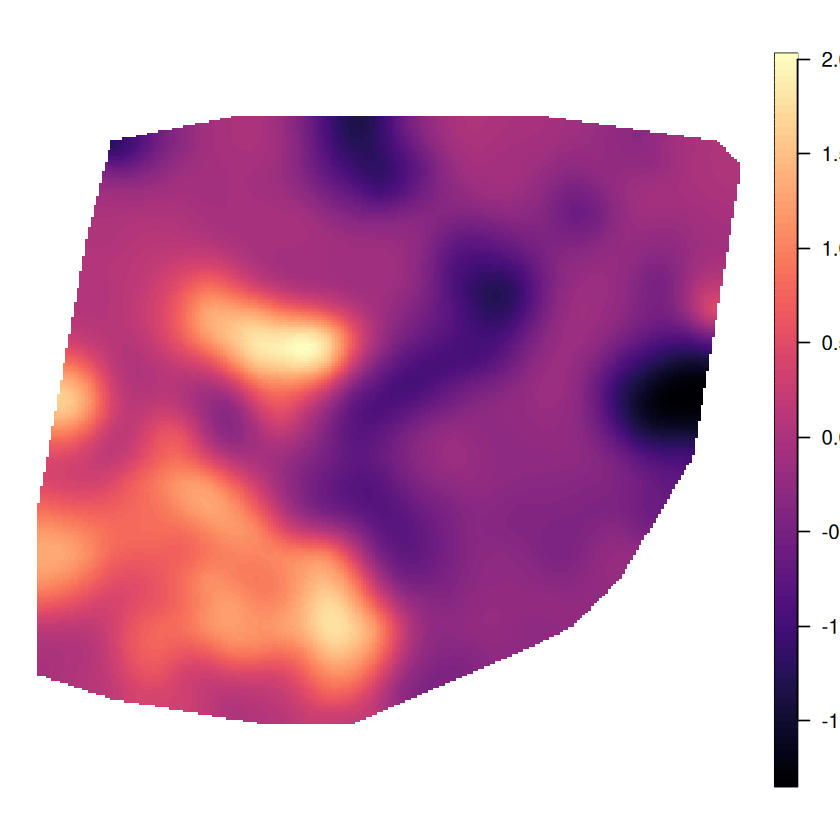

In [18]:
# Select fPCs associated with the ERBB2 gene
erb22 <- (fpca_model$scores[,1:3] %*% t(fPCs[,1:3]))[idx.HER2,]

# Static plot
par(mar = c(0.5, 0.5, 0.5, 3), oma = c(0, 0, 0, 0), mfrow = c(1,1))
plot(
    fe_function(domain = mesh_tissue, coeff=erb22, type = "P1"), 
    palette = magma, 
    frame.plot = FALSE, xaxt = "n", yaxt = "n"
)
image.plot(
    legend.only = TRUE,
    zlim        = range(erb22, na.rm = T), 
    col         = palette_, 
    legend.args = list(side = 4), 
    legend.lab  = "", 
    legend.mar  = 2.25
)

<div style="text-align: center;">
Figure 6: Smooth reconstruction of the original gene activation map associated to the *ERBB2* gene using the extracted fPCs.
</div>

Moreover, examining the score vector associated with the *ERBB2* gene reveals a strong activation along fPC1, which is consistent with the interpretation of fPC1 as capturing cancer-related variation.

[1] 15.2798320 -4.5316538 -1.6403999 -1.1276803 -2.6486349 -0.5792741

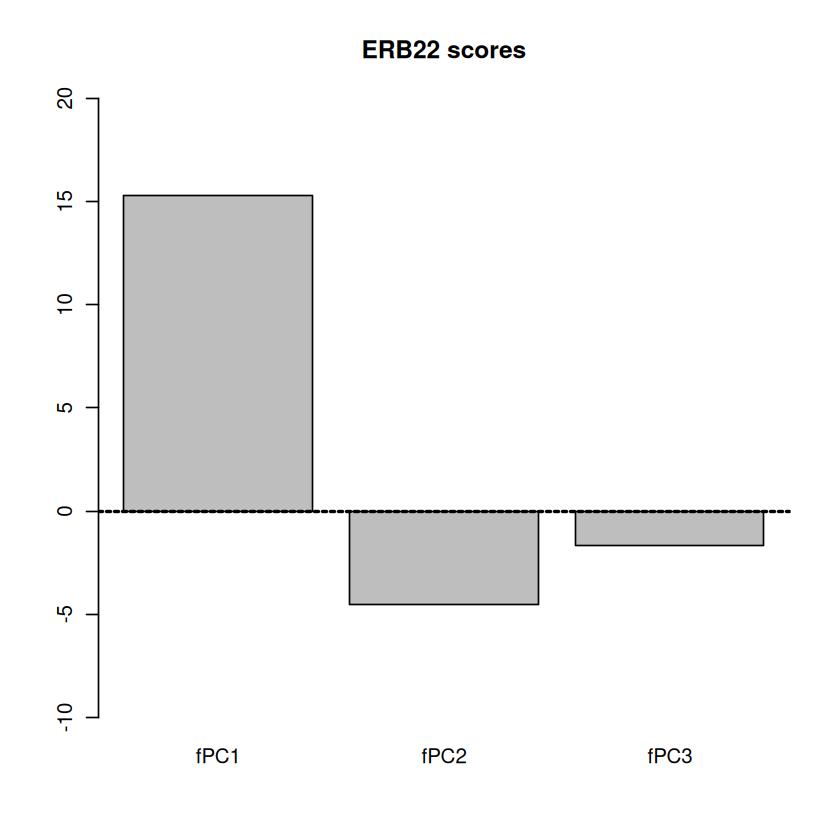

In [19]:
# Scores
fpca_model$scores[idx.HER2,]

# Static plot
labels <- paste0("fPC", 1:3)
barplot(fpca_model$scores[idx.HER2,1:3], names.arg = labels, main = "ERB22 scores", ylim = c(-10, 20))
abline(h = 0, lty = 2, lwd = 2)

*ERBB2* is the gene with the highest score along fPC1, further supporting its association with cancer-related activity captured by this component, as shown in the figure below.

[1] "ERBB2"

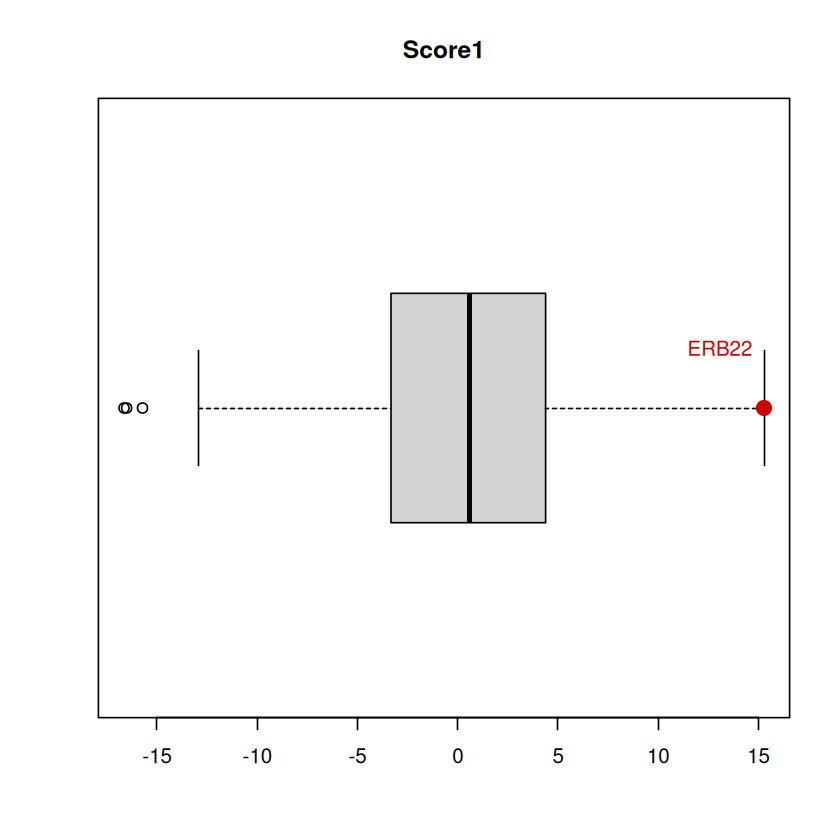

In [20]:
# Gene names
gene_names[which.max(fpca_model$scores[,1])]

# Static plot
boxplot(fpca_model$scores[,1], horizontal = TRUE, main = "Score1")
points(max(fpca_model$scores[,1]), 1, col = "red3", pch = 19, cex = 1.5)
text(max(fpca_model$scores[,1]), 1.1, labels = "ERB22", col = "red3", pos = 2)

<div style="text-align: center;">
Figure 7: Scores for the *ERBB2* gene.
</div>

## References

<div id="refs" class="references csl-bib-body hanging-indent"
data-entry-spacing="0" data-line-spacing="2" role="list">
<div id="ref-lila2016smooth" class="csl-entry" role="listitem">
Lila, E., Aston, J. A., &amp; Sangalli, L. M. (2016). Smooth principal
component analysis over two-dimensional manifolds with an application to
neuroimaging. <em>Annals of Applied Statistics</em>, <em>10</em>(4),
1854–1879. <a
href="https://doi.org/10.1214/16-AOAS975">https://doi.org/10.1214/16-AOAS975</a>
</div>
<div id="ref-lindgren2025fmesher" class="csl-entry" role="listitem">
Lindgren, F. (2025). <em>Fmesher: <span>T</span>riangle meshes and
related geometry tools</em>. url: <a
href="https://CRAN.R-project.org/package=fmesher"
class="uri">https://CRAN.R-project.org/package=fmesher</a>.
</div>
<div id="ref-palummo2026fdapde" class="csl-entry" role="listitem">
Palummo, A., Clemente, A., Sangalli, E., Arnone, Formaggia, L., &amp;
Maria, L. (2025). <em>fdaPDE: <span>P</span>hysics-informed statistical
learning</em>. url: <a href="https://github.com/fdaPDE/fdaPDE-R"
class="uri">https://github.com/fdaPDE/fdaPDE-R</a>.
</div>
<div id="ref-sangalli2021spatial" class="csl-entry" role="listitem">
Sangalli, L. M. (2021). Spatial regression with partial differential
equation regularisation. <em>International Statistical Review</em>,
<em>89</em>(3), 505–531. <a
href="https://doi.org/10.1111/insr.12444">https://doi.org/10.1111/insr.12444</a>
</div>
<div id="ref-shang2022spatially" class="csl-entry" role="listitem">
Shang, L., &amp; Zhou, X. (2022). Spatially aware dimension reduction
for spatial transcriptomics. <em>Nature Communications</em>,
<em>13</em>(1).
</div>
<div id="ref-shewchuk2025RTriangle" class="csl-entry" role="listitem">
Shewchuk, J. R., &amp; Sterratt, D. C. (2025). <em>RTriangle - a
2<span>D</span> quality mesh generator and <span>D</span>elaunay
triangulator</em>. url: <a
href="https://CRAN.R-project.org/package=RTriangle"
class="uri">https://CRAN.R-project.org/package=RTriangle</a>.
</div>
</div>